<a href="https://colab.research.google.com/github/dzamaadam-afk/analyzy/blob/main/Prenostepla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

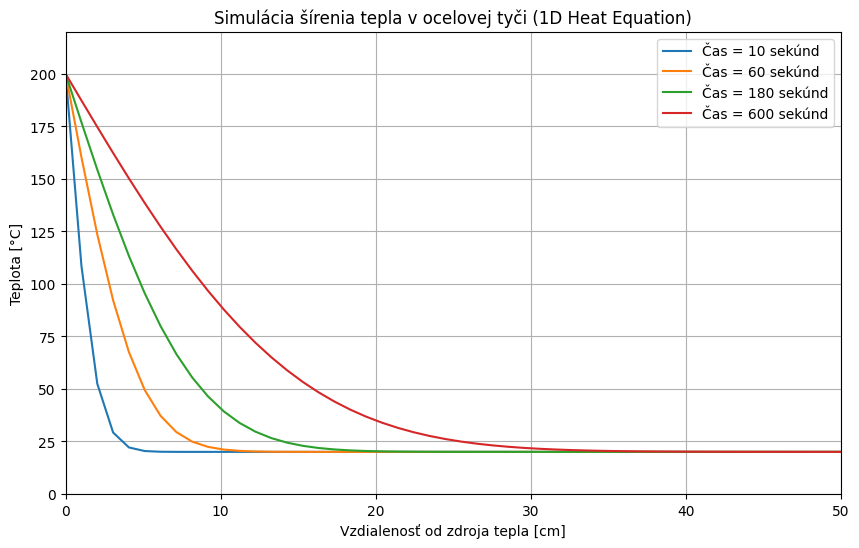

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. FYZIKÁLNE PARAMETRE (Vlastnosti materiálu - napr. oceľ)
dlzka_tyce = 0.5  # Tyč má 50 cm (0.5 metra)
pocet_bodov = 50  # Na koľko dielikov tyč rozdelíme (vzdialenostný krok)
dx = dlzka_tyce / (pocet_bodov - 1)

alfa = 1.11e-5  # Tepelná vodivosť (Thermal diffusivity pre oceľ [m^2/s])

cas_celkovo = 600  # Budeme simulovať 600 sekúnd (10 minút)
dt = 0.1  # Časový krok v sekundách
pocet_krokov = int(cas_celkovo / dt)

# 2. POČIATOČNÉ A OKRAJOVÉ PODMIENKY (Matematické zadanie)
T = np.ones(pocet_bodov) * 20.0  # Na začiatku má celá tyč 20 °C
T[0] = 200.0  # Ľavý koniec tyče okamžite zahrejeme na 200 °C (okrajová podmienka)
T[-1] = 20.0  # Pravý koniec zostáva chladený na 20 °C

# 3. NUMERICKÉ RIEŠENIE PARCIÁLNEJ DIFERENCIÁLNEJ ROVNICE (Metóda konečných diferencií)
# Sledujeme teplotu v 4 rôznych časoch, aby sme videli progres
casy_na_vykreslenie = [10, 60, 180, 600]  # v sekundách
Teploty_v_case = {}

T_aktualna = T.copy()

for krok in range(1, pocet_krokov + 1):
    T_nova = T_aktualna.copy()

    # Prechádzame vnútorné body tyče a počítame derivácie druhej rýchlosti
    for i in range(1, pocet_bodov - 1):
        T_nova[i] = T_aktualna[i] + alfa * dt / (dx**2) * (T_aktualna[i+1] - 2*T_aktualna[i] + T_aktualna[i-1])

    T_aktualna = T_nova.copy()

    # Uložíme si stav v konkrétnych časoch
    aktualny_cas = krok * dt
    for c in casy_na_vykreslenie:
        if abs(aktualny_cas - c) < dt/2:
            Teploty_v_case[c] = T_aktualna.copy()

# 4. VYKRESLENIE GRAFU ŠÍRENIA TEPLA
plt.figure(figsize=(10, 6))
x_osi = np.linspace(0, dlzka_tyce, pocet_bodov) * 100  # prevod na centimetre

# Vykreslíme krivky pre jednotlivé časy
for c in casy_na_vykreslenie:
    if c in Teploty_v_case:
        plt.plot(x_osi, Teploty_v_case[c], label=f"Čas = {c} sekúnd")

plt.title("Simulácia šírenia tepla v ocelovej tyči (1D Heat Equation)")
plt.xlabel("Vzdialenosť od zdroja tepla [cm]")
plt.ylabel("Teplota [°C]")
plt.xlim(0, dlzka_tyce * 100)
plt.ylim(0, 220)
plt.legend()
plt.grid(True)
plt.show()